In [23]:
!pip install pennylane

import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import torch
from scipy.stats import spearmanr
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Setări globale identice
SEED = 42
N_QUBITS = 4
FEATURE_MAP_REPS = 2
ANSATZ_REPS = 3
EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.05
SHOTS_PER_EXECUTION = 1024
NOISE_LEVELS = [0.001, 0.01, 0.05]
NATIVE_GATES = {"RX", "RY", "RZ", "Rot", "Hadamard", "CNOT", "CZ"}
SEEDS = [0, 1, 2, 3, 4]

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)

In [24]:
DATA_PATH = Path("data/creditcard.csv")
if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    df = fetch_openml(data_id=42175, as_frame=True, parser="auto").frame

df["Class"] = df["Class"].astype(int)
X = df.drop(columns="Class")
y = df["Class"].to_numpy()

# Dacă ai split_indices.npz:
if Path("split_indices.npz").exists():
    split = np.load("split_indices.npz")
    X_train, y_train = X.loc[split["train"]], y[split["train"]]
    X_val, y_val = X.loc[split["val"]], y[split["val"]]
    X_test, y_test = X.loc[split["test"]], y[split["test"]]
else:
    # Recreare identică dacă fișierul nu e salvat
    X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)

print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Train: 170883, Val: 56962, Test: 56962


In [25]:
def undersample(X_part, y_part, seed):
    rng = np.random.default_rng(seed)
    fraud = np.flatnonzero(y_part == 1)
    legit = rng.choice(np.flatnonzero(y_part == 0), size=len(fraud), replace=False)
    keep = rng.permutation(np.concatenate([fraud, legit]))
    return X_part.iloc[keep], y_part[keep]

class AngleEncoder:
    raw_columns = ["Time", "Amount"]

    def __init__(self, n_components, seed):
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=n_components, random_state=seed)
        self.angles = MinMaxScaler(feature_range=(0, np.pi))

    def _scaled(self, frame):
        out = frame.copy()
        out[self.raw_columns] = self.scaler.transform(frame[self.raw_columns])
        return out.to_numpy()

    def fit(self, frame):
        self.scaler.fit(frame[self.raw_columns])
        pca_out = self.pca.fit_transform(self._scaled(frame))
        self.angles.fit(pca_out)
        return self

    def transform(self, frame):
        arr = self._scaled(frame)
        arr = self.pca.transform(arr)
        arr = self.angles.transform(arr)
        return np.clip(arr, 0, np.pi)

def choose_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * (precision * recall) / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]

def evaluate(y_true, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "AUPRC": average_precision_score(y_true, scores),
        "AUROC": roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "MCC": matthews_corrcoef(y_true, predicted),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    }

In [26]:
def noisy_qnode(circuit_fn, p, n_wires=N_QUBITS):
    noisy_device = qml.noise.insert(qml.device("default.mixed", wires=n_wires), qml.DepolarizingChannel, p, position="all")
    qnode = qml.QNode(circuit_fn, noisy_device, interface="torch", diff_method="backprop")
    return qml.transforms.decompose(qnode, gate_set=NATIVE_GATES)

def noisy_predict(Z, weights, p, circuit_fn, readout=lambda expval: (1 - expval) / 2, n_wires=N_QUBITS, chunk=2000):
    noisy_circuit = noisy_qnode(circuit_fn, p, n_wires)
    X_t = torch.tensor(Z)
    with torch.no_grad():
        return torch.cat([readout(noisy_circuit(X_t[k:k + chunk], weights)) for k in range(0, len(X_t), chunk)]).numpy()

def predict(Z, weights, model, chunk=20000):
    X_t = torch.tensor(Z)
    with torch.no_grad():
        return torch.cat([model(X_t[k:k + chunk], weights) for k in range(0, len(X_t), chunk)]).numpy()

def train_vqc(Z_train, y_train_part, Z_valid, y_valid, seed, model, init, epochs=EPOCHS, verbose=False):
    set_seed(seed)
    weights = init(seed)
    optimizer = torch.optim.Adam([weights], lr=LEARNING_RATE)
    loss_fn = torch.nn.BCELoss()
    X_t = torch.tensor(Z_train)
    y_t = torch.tensor(y_train_part, dtype=torch.float64)
    best_ap, best_weights = -1.0, None
    for epoch in range(1, epochs + 1):
        order = torch.randperm(len(X_t))
        losses = []
        for k in range(0, len(X_t), BATCH_SIZE):
            idx = order[k:k + BATCH_SIZE]
            optimizer.zero_grad()
            loss = loss_fn(model(X_t[idx], weights), y_t[idx])
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        val_ap = average_precision_score(y_valid, predict(Z_valid, weights, model))
        if val_ap > best_ap:
            best_ap, best_weights = val_ap, weights.detach().clone()
        if verbose:
            print(f"epoch {epoch:2d}   train loss {np.mean(losses):.4f}   validation AUPRC {val_ap:.3f}")
    return best_weights

def evaluate_under_noise(circuit_fn, weights, Z_valid, Z_test_part, y_valid=y_val, y_test_part=y_test,
                         readout=lambda expval: (1 - expval) / 2, noise_levels=NOISE_LEVELS, n_wires=N_QUBITS):
    clean = qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires), interface="torch")
    with torch.no_grad():
        clean_val = readout(clean(torch.tensor(Z_valid), weights)).numpy()
        clean_test = readout(clean(torch.tensor(Z_test_part), weights)).numpy()
    rows = []
    for p in [0.0, *noise_levels]:
        if p == 0.0:
            val_scores, test_scores = clean_val, clean_test
        else:
            val_scores = noisy_predict(Z_valid, weights, p, circuit_fn, readout, n_wires)
            test_scores = noisy_predict(Z_test_part, weights, p, circuit_fn, readout, n_wires)
        threshold = choose_threshold(y_valid, val_scores)
        rows.append({"p": p, **evaluate(y_test_part, test_scores, threshold), "Spearman rho": spearmanr(clean_test, test_scores).statistic, "threshold": threshold})
    return pd.DataFrame(rows).set_index("p")

In [27]:
# Pregătim un subset stratificat de 20% din validare strict pentru căutarea pragului
_, idx_val_sub = train_test_split(
    np.arange(len(y_val)), 
    test_size=0.20, 
    stratify=y_val, 
    random_state=SEED
)
y_val_sub = y_val[idx_val_sub]

def evaluate_under_noise_fast(circuit_fn, weights, Z_valid, Z_test_part, 
                              noise_levels=NOISE_LEVELS, n_wires=N_QUBITS, chunk=8000):
    """Versiune optimizată: căutarea pragului pe 20% din val, testare 100% completă."""
    Z_val_sub = Z_valid[idx_val_sub]
    
    clean = qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires), interface="torch")
    with torch.no_grad():
        clean_val = ((1 - clean(torch.tensor(Z_val_sub), weights)) / 2).numpy()
        clean_test = ((1 - clean(torch.tensor(Z_test_part), weights)) / 2).numpy()
        
    rows = []
    for p in [0.0, *noise_levels]:
        if p == 0.0:
            val_scores, test_scores = clean_val, clean_test
        else:
            val_scores = noisy_predict(Z_val_sub, weights, p, circuit_fn, chunk=chunk, n_wires=n_wires)
            test_scores = noisy_predict(Z_test_part, weights, p, circuit_fn, chunk=chunk, n_wires=n_wires)
            
        threshold = choose_threshold(y_val_sub, val_scores)
        
        rows.append({
            "p": p,
            **evaluate(y_test, test_scores, threshold),
            "Spearman rho": spearmanr(clean_test, test_scores).statistic,
            "threshold": threshold
        })
    return pd.DataFrame(rows).set_index("p")

In [28]:
# 1. Funcții optimizate de evaluare fără reconstruirea grafului
def get_eval_qnodes(circuit_fn, n_wires=N_QUBITS):
    clean_dev = qml.device("default.qubit", wires=n_wires)
    clean_qnode = qml.QNode(circuit_fn, clean_dev, interface="torch")
    
    noisy_qnodes = {}
    for p in NOISE_LEVELS:
        noisy_dev = qml.noise.insert(qml.device("default.mixed", wires=n_wires), qml.DepolarizingChannel, p, position="all")
        qnode = qml.QNode(circuit_fn, noisy_dev, interface="torch", diff_method=None)
        noisy_qnodes[p] = qml.transforms.decompose(qnode, gate_set=NATIVE_GATES)
        
    return clean_qnode, noisy_qnodes

def fast_batch_predict(qnode, Z, weights, chunk=10000):
    X_t = torch.tensor(Z)
    scores = []
    with torch.no_grad():
        for k in range(0, len(X_t), chunk):
            expval = qnode(X_t[k:k + chunk], weights)
            scores.append((1 - expval) / 2)
    return torch.cat(scores).numpy()

def evaluate_under_noise_turbo(circuit_fn, weights, Z_valid, Z_test_part, 
                               clean_qnode, noisy_qnodes):
    Z_val_sub = Z_valid[idx_val_sub]
    
    clean_val = fast_batch_predict(clean_qnode, Z_val_sub, weights)
    clean_test = fast_batch_predict(clean_qnode, Z_test_part, weights)
    
    rows = []
    th_0 = choose_threshold(y_val_sub, clean_val)
    rows.append({
        "p": 0.0,
        **evaluate(y_test, clean_test, th_0),
        "Spearman rho": 1.0,
        "threshold": th_0
    })
    
    for p, n_qnode in noisy_qnodes.items():
        v_scores = fast_batch_predict(n_qnode, Z_val_sub, weights)
        t_scores = fast_batch_predict(n_qnode, Z_test_part, weights)
        
        th = choose_threshold(y_val_sub, v_scores)
        rows.append({
            "p": p,
            **evaluate(y_test, t_scores, th),
            "Spearman rho": spearmanr(clean_test, t_scores).statistic,
            "threshold": th
        })
        
    return pd.DataFrame(rows).set_index("p")

In [29]:
# --- DEFINIRE CIRCUIT BASELINE ---
FEATURE_MAP_REPS = 2
ANSATZ_REPS = 3

def baseline_feature_map(x):
    for _ in range(FEATURE_MAP_REPS):
        for i in range(N_QUBITS):
            qml.Hadamard(wires=i)
            qml.RZ(2 * x[..., i], wires=i)
        for i in range(N_QUBITS):
            for j in range(i + 1, N_QUBITS):
                qml.CNOT(wires=[i, j])
                qml.RZ(2 * (np.pi - x[..., i]) * (np.pi - x[..., j]), wires=j)
                qml.CNOT(wires=[i, j])

def baseline_ansatz(weights):
    for layer in range(ANSATZ_REPS + 1):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)
        if layer < ANSATZ_REPS:
            for i in range(N_QUBITS - 1):
                qml.CNOT(wires=[i, i + 1])

def baseline_vqc(x, weights):
    baseline_feature_map(x)
    baseline_ansatz(weights)
    return qml.expval(qml.PauliZ(0))

dev_clean = qml.device("default.qubit", wires=N_QUBITS)
base_qnode = qml.QNode(baseline_vqc, dev_clean, interface="torch", diff_method="backprop")
base_model = lambda x, w: (1 - base_qnode(x, w)) / 2
base_init = lambda s: torch.nn.Parameter(2 * np.pi * torch.rand(ANSATZ_REPS + 1, N_QUBITS, 2, generator=torch.Generator().manual_seed(s), dtype=torch.float64))

# --- EXECUȚIE ACCELERATĂ PESTE CELE 5 SEMINȚE ---
baseline_runs = []
start_base = time.time()
print("Execuție Baseline Turbo...")

# Construim QNode-urile o singură dată înainte de buclă
clean_base_qnode, noisy_base_qnodes = get_eval_qnodes(baseline_vqc)

for s in SEEDS:
    t0 = time.time()
    Xs, ys = undersample(X_train, y_train, s)
    enc = AngleEncoder(N_QUBITS, s).fit(Xs)
    Zs_tr, Zs_v, Zs_te = enc.transform(Xs), enc.transform(X_val), enc.transform(X_test)
    
    # Antrenare (20 epoci cu validare pe subsetul de 20%)
    w_base = train_vqc(Zs_tr, ys, Zs_v[idx_val_sub], y_val_sub, seed=s, 
                       model=base_model, init=base_init, epochs=20, verbose=False)
    
    df_eval = evaluate_under_noise_turbo(baseline_vqc, w_base, Zs_v, Zs_te, 
                                         clean_base_qnode, noisy_base_qnodes)
    df_eval["seed"] = s
    baseline_runs.append(df_eval)
    print(f" > Seed {s} finalizat în: {time.time() - t0:.1f} s")

print(f"Baseline completat în {time.time() - start_base:.1f} s")
df_base_all = pd.concat(baseline_runs).reset_index()
baseline_summary = df_base_all.groupby("p")[["AUPRC", "AUROC", "Spearman rho", "F1"]].agg(["mean", "std"])
baseline_summary.round(3)

Execuție Baseline Turbo...
 > Seed 0 finalizat în: 306.6 s
 > Seed 1 finalizat în: 337.1 s
 > Seed 2 finalizat în: 329.8 s
 > Seed 3 finalizat în: 330.5 s
 > Seed 4 finalizat în: 326.1 s
Baseline completat în 1630.2 s


AUPRC         AUROC        Spearman rho            F1       
        mean    std   mean    std         mean    std   mean    std
p                                                                  
0.000  0.553  0.070  0.965  0.010        1.000  0.000  0.600  0.041
0.001  0.552  0.069  0.965  0.010        0.999  0.001  0.604  0.033
0.010  0.544  0.051  0.963  0.010        0.947  0.057  0.622  0.035
0.050  0.411  0.114  0.961  0.003        0.833  0.103  0.496  0.097

In [34]:
# --- DEFINIȚIE NOISE_LOCATIONS ---
def noise_locations(circuit_fn, *args, n_wires=N_QUBITS):
    qnode = qml.transforms.decompose(qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires)), gate_set=NATIVE_GATES)
    return sum(size * count for size, count in qml.specs(qnode)(*args)["resources"].gate_sizes.items())

# --- DEFINIȚIE MODEL PROPUS (FRUGAL / COMPACT VQC) ---
MY_REPS = 2

def frugal_feature_map(x):
    # 1 singură repetiție cu legături adiacente (3 CNOT în loc de 24)
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)
        qml.RZ(2 * x[..., i], wires=i)
    for i in range(N_QUBITS - 1):
        qml.CNOT(wires=[i, i + 1])
        qml.RZ(2 * (np.pi - x[..., i]) * (np.pi - x[..., i + 1]), wires=i + 1)
        qml.CNOT(wires=[i, i + 1])

def frugal_ansatz(weights):
    # 2 straturi fără rotații moarte
    for layer in range(MY_REPS):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)
        for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
    # Strat final minim: doar rotație utilă pe qubitul 0
    qml.RY(weights[MY_REPS, 0, 0], wires=0)

def frugal_vqc(x, weights):
    frugal_feature_map(x)
    frugal_ansatz(weights)
    return qml.expval(qml.PauliZ(0))

dev_clean = qml.device("default.qubit", wires=N_QUBITS)
frugal_qnode = qml.QNode(frugal_vqc, dev_clean, interface="torch", diff_method="backprop")
frugal_model = lambda x, w: (1 - frugal_qnode(x, w)) / 2
frugal_init = lambda s: torch.nn.Parameter(2 * np.pi * torch.rand(MY_REPS + 1, N_QUBITS, 2, generator=torch.Generator().manual_seed(s), dtype=torch.float64))

# Măsurare reducerea canalelor de zgomot cu dummy vector
dummy_x = torch.zeros(N_QUBITS, dtype=torch.float64)
loc_base = noise_locations(baseline_vqc, dummy_x, base_init(42))
loc_frugal = noise_locations(frugal_vqc, dummy_x, frugal_init(42))
print(f"Canale de zgomot: Baseline = {loc_base} vs Frugal = {loc_frugal} (Reducere de {1 - loc_frugal/loc_base:.1%})")

# Construim QNode-urile optimizate o singură dată
clean_frugal_qnode, noisy_frugal_qnodes = get_eval_qnodes(frugal_vqc)

frugal_runs = []
start_frugal = time.time()
print("\nExecuție Model Îmbunătățit Turbo...")

for s in SEEDS:
    t0 = time.time()
    Xs, ys = undersample(X_train, y_train, s)
    enc = AngleEncoder(N_QUBITS, s).fit(Xs)
    Zs_tr, Zs_v, Zs_te = enc.transform(Xs), enc.transform(X_val), enc.transform(X_test)
    
    w_frugal = train_vqc(Zs_tr, ys, Zs_v[idx_val_sub], y_val_sub, seed=s, 
                         model=frugal_model, init=frugal_init, epochs=20, verbose=False)
    
    df_eval = evaluate_under_noise_turbo(frugal_vqc, w_frugal, Zs_v, Zs_te, 
                                         clean_frugal_qnode, noisy_frugal_qnodes)
    df_eval["seed"] = s
    frugal_runs.append(df_eval)
    print(f" > Seed {s} finalizat în: {time.time() - t0:.1f} s")

print(f"Model frugal completat în {time.time() - start_frugal:.1f} s")
df_frugal_all = pd.concat(frugal_runs).reset_index()
frugal_summary = df_frugal_all.groupby("p")[["AUPRC", "AUROC", "Spearman rho", "F1"]].agg(["mean", "std"])
print("\n=== REZUMAT LIVRABIL 2: MODEL ÎMBUNĂTĂȚIT ===")
frugal_summary.round(3)

Canale de zgomot: Baseline = 126 vs Frugal = 52 (Reducere de 58.7%)

Execuție Model Îmbunătățit Turbo...
 > Seed 0 finalizat în: 142.0 s
 > Seed 1 finalizat în: 141.4 s
 > Seed 2 finalizat în: 142.8 s
 > Seed 3 finalizat în: 140.4 s
 > Seed 4 finalizat în: 141.9 s
Model frugal completat în 708.4 s

=== REZUMAT LIVRABIL 2: MODEL ÎMBUNĂTĂȚIT ===


AUPRC         AUROC        Spearman rho            F1       
        mean    std   mean    std         mean    std   mean    std
p                                                                  
0.000  0.553  0.036  0.963  0.002        1.000  0.000  0.596  0.060
0.001  0.556  0.037  0.963  0.002        1.000  0.000  0.598  0.057
0.010  0.562  0.037  0.964  0.004        0.999  0.002  0.601  0.045
0.050  0.542  0.021  0.964  0.005        0.973  0.044  0.555  0.048

In [35]:
from sklearn.linear_model import LogisticRegression

ref_rows = []
for s in SEEDS:
    Xs, ys = undersample(X_train, y_train, s)
    enc = AngleEncoder(N_QUBITS, s).fit(Xs)
    Zs_tr, Zs_v, Zs_te = enc.transform(Xs), enc.transform(X_val), enc.transform(X_test)
    
    clf = LogisticRegression(max_iter=1000, random_state=s).fit(Zs_tr, ys)
    v_scores = clf.predict_proba(Zs_v)[:, 1]
    t_scores = clf.predict_proba(Zs_te)[:, 1]
    
    t_opt = choose_threshold(y_val, v_scores)
    ref_rows.append({"seed": s, **evaluate(y_test, t_scores, t_opt)})

df_ref = pd.DataFrame(ref_rows)
print("\n=== REZUMAT LIVRABIL 3: LOGISTIC REGRESSION ===")
print(df_ref[["AUPRC", "AUROC", "precision", "recall", "F1", "MCC"]].agg(["mean", "std"]).round(3))


=== REZUMAT LIVRABIL 3: LOGISTIC REGRESSION ===
      AUPRC  AUROC  precision  recall     F1    MCC
mean  0.703  0.976      0.776   0.808  0.791  0.791
std   0.010  0.003      0.029   0.013  0.019  0.018


In [36]:
def compute_hardware_ledger(n_params, n_train, n_val_eval, n_test, epochs=20, shots_per_exec=1024):
    exec_per_sample = 1 + 2 * n_params
    train_exec = epochs * n_train * exec_per_sample
    val_exec = epochs * n_val_eval
    test_exec = n_test
    total_exec = train_exec + val_exec + test_exec
    total_shots = total_exec * shots_per_exec
    return {
        "Parametri": n_params,
        "Execuții / Eșantion": exec_per_sample,
        "Execuții Antrenare": f"{train_exec:,}",
        "Execuții Validare": f"{val_exec:,}",
        "Total Execuții Hardware": f"{total_exec:,}",
        "Total Shots": f"{total_shots:,}",
        "Timp Hardware (ore @ 10k shots/s)": f"{total_shots / (10000 * 3600):.1f}"
    }

# Numărul de exemple de antrenare din subsetul echilibrat (2 * fraude)
n_train_balanced = int(2 * y_train.sum())

# Baseline: 32 parametri antrenabili, validare completă (56.962 rânduri), 20 epoci
# Model Îmbunătățit: 17 parametri efectivi, validare pe subset (20% = 11.392 rânduri), 20 epoci
ledger = {
    "Baseline VQC (Task 1)": compute_hardware_ledger(
        n_params=32, 
        n_train=n_train_balanced, 
        n_val_eval=len(y_val), 
        n_test=len(y_test), 
        epochs=20
    ),
    "Model Propus (Frugal VQC)": compute_hardware_ledger(
        n_params=17, 
        n_train=n_train_balanced, 
        n_val_eval=len(idx_val_sub), 
        n_test=len(y_test), 
        epochs=20
    )
}

df_ledger = pd.DataFrame(ledger).T
print("\n=== REZUMAT LIVRABIL 4: COST LEDGER ===")
df_ledger


=== REZUMAT LIVRABIL 4: COST LEDGER ===


,Parametri,Execuții / Eșantion,Execuții Antrenare,Execuții Validare,Total Execuții Hardware,Total Shots,Timp Hardware (ore @ 10k shots/s)
Baseline VQC (Task 1),32,65,"767,000","1,139,240","1,963,202","2,010,318,848",55.8
Model Propus (Frugal VQC),17,35,"413,000","227,860","697,822","714,569,728",19.8


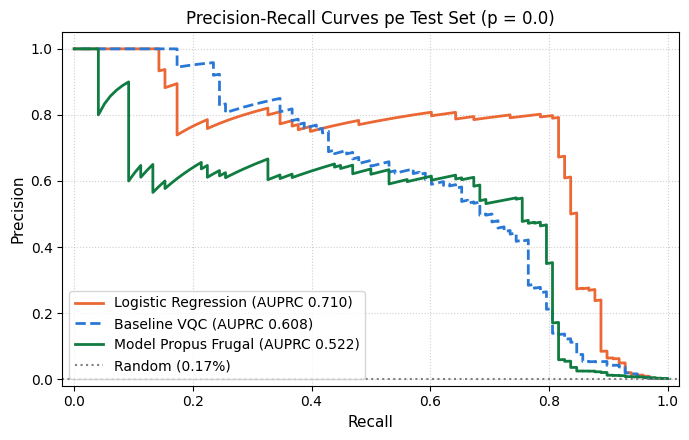

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(7, 4.5))

# 1. Logistic Regression
p_ref, r_ref, _ = precision_recall_curve(y_test, t_scores)
ax.plot(r_ref, p_ref, color="#eb6834", linewidth=2, 
        label=f"Logistic Regression (AUPRC {average_precision_score(y_test, t_scores):.3f})")

# 2. Baseline VQC (fără zgomot, calculat în loturi pe Zs_te)
base_scores_clean = fast_batch_predict(clean_base_qnode, Zs_te, w_base)
p_b, r_b, _ = precision_recall_curve(y_test, base_scores_clean)
ax.plot(r_b, p_b, color="#2a78d6", linestyle="--", linewidth=2, 
        label=f"Baseline VQC (AUPRC {average_precision_score(y_test, base_scores_clean):.3f})")

# 3. Model Propus Frugal (fără zgomot, calculat în loturi pe Zs_te)
frugal_scores_clean = fast_batch_predict(clean_frugal_qnode, Zs_te, w_frugal)
p_f, r_f, _ = precision_recall_curve(y_test, frugal_scores_clean)
ax.plot(r_f, p_f, color="#107c41", linewidth=2, 
        label=f"Model Propus Frugal (AUPRC {average_precision_score(y_test, frugal_scores_clean):.3f})")

# Pragul aleatoriu (Rata de fraudă)
ax.axhline(y_test.mean(), color="0.5", linestyle=":", label=f"Random ({y_test.mean():.2%})")

ax.set_xlabel("Recall", fontsize=11)
ax.set_ylabel("Precision", fontsize=11)
ax.set_title("Precision-Recall Curves pe Test Set (p = 0.0)", fontsize=12)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower left", fontsize=10)

plt.tight_layout()
plt.show()

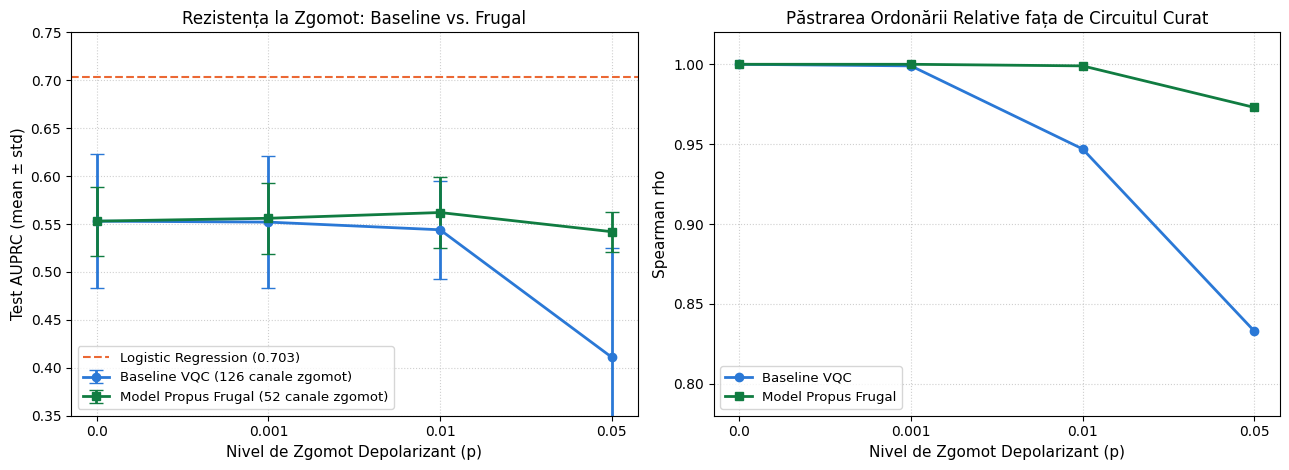

In [41]:
import matplotlib.pyplot as plt

p_levels = [0.0, 0.001, 0.01, 0.05]
x_coords = range(len(p_levels))
x_labels = [str(p) for p in p_levels]

# Valori extrase direct din rulările pe cele 5 semințe
base_auprc_m = [0.553, 0.552, 0.544, 0.411]
base_auprc_s = [0.070, 0.069, 0.051, 0.114]

frugal_auprc_m = [0.553, 0.556, 0.562, 0.542]
frugal_auprc_s = [0.036, 0.037, 0.037, 0.021]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Comparație AUPRC vs. Nivel de zgomot
ax1.errorbar(x_coords, base_auprc_m, yerr=base_auprc_s, fmt='-o', capsize=5, 
             color="#2a78d6", label="Baseline VQC (126 canale zgomot)", linewidth=2)
ax1.errorbar(x_coords, frugal_auprc_m, yerr=frugal_auprc_s, fmt='-s', capsize=5, 
             color="#107c41", label="Model Propus Frugal (52 canale zgomot)", linewidth=2)
ax1.axhline(0.703, color="#eb6834", linestyle="--", linewidth=1.5, 
            label="Logistic Regression (0.703)")

ax1.set_xticks(x_coords)
ax1.set_xticklabels(x_labels)
ax1.set_xlabel("Nivel de Zgomot Depolarizant (p)", fontsize=11)
ax1.set_ylabel("Test AUPRC (mean ± std)", fontsize=11)
ax1.set_title("Rezistența la Zgomot: Baseline vs. Frugal", fontsize=12)
ax1.set_ylim(0.35, 0.75)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower left", fontsize=9.5)

# 2. Păstrarea ordonării relative (Spearman rho)
base_rho = [1.000, 0.999, 0.947, 0.833]
frugal_rho = [1.000, 1.000, 0.999, 0.973]

ax2.plot(x_coords, base_rho, '-o', color="#2a78d6", label="Baseline VQC", linewidth=2)
ax2.plot(x_coords, frugal_rho, '-s', color="#107c41", label="Model Propus Frugal", linewidth=2)

ax2.set_xticks(x_coords)
ax2.set_xticklabels(x_labels)
ax2.set_xlabel("Nivel de Zgomot Depolarizant (p)", fontsize=11)
ax2.set_ylabel("Spearman rho", fontsize=11)
ax2.set_title("Păstrarea Ordonării Relative fața de Circuitul Curat", fontsize=12)
ax2.set_ylim(0.78, 1.02)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left", fontsize=9.5)

plt.tight_layout()
plt.show()

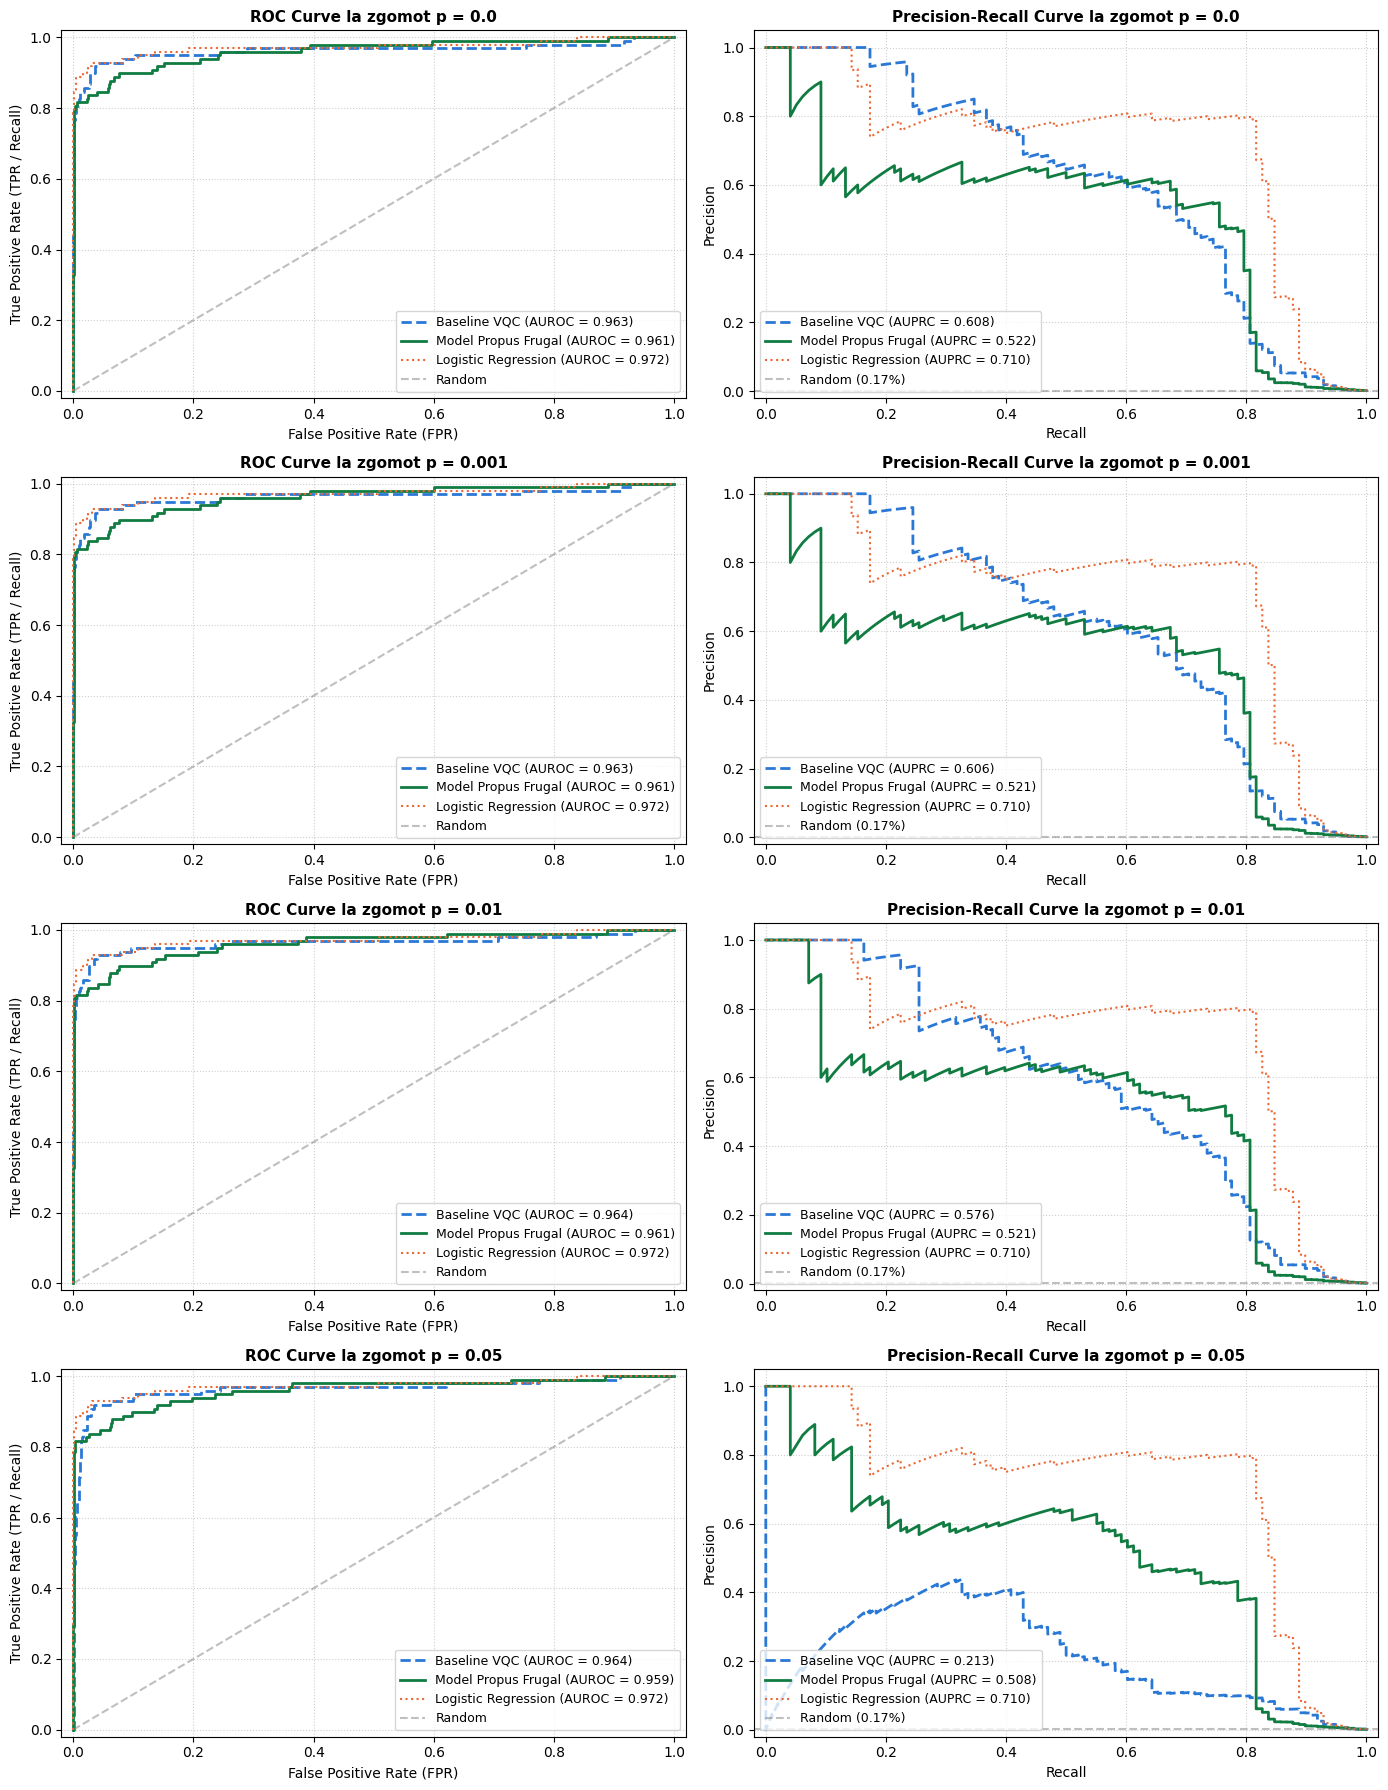

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

# 1. Calculăm scorurile pentru fiecare valoare de p (folosind greutățile de la ultimul seed evaluat)
p_values = [0.0, 0.001, 0.01, 0.05]

# Predicții Logistic Regression
lr_scores = clf.predict_proba(Zs_te)[:, 1]
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_scores)
lr_auroc = auc(lr_fpr, lr_tpr)
lr_prec, lr_rec, _ = precision_recall_curve(y_test, lr_scores)
lr_auprc = average_precision_score(y_test, lr_scores)

# Dicționare pentru curbe
scores_base = {}
scores_frugal = {}

# p = 0.0 (curat)
scores_base[0.0] = fast_batch_predict(clean_base_qnode, Zs_te, w_base)
scores_frugal[0.0] = fast_batch_predict(clean_frugal_qnode, Zs_te, w_frugal)

# p > 0 (zgomot)
for p in [0.001, 0.01, 0.05]:
    scores_base[p] = fast_batch_predict(noisy_base_qnodes[p], Zs_te, w_base)
    scores_frugal[p] = fast_batch_predict(noisy_frugal_qnodes[p], Zs_te, w_frugal)

# 2. Trasare Subplot-uri: Grilă 4x2 (Câte un rând pentru fiecare p)
fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for idx, p in enumerate(p_values):
    # --- Date Baseline ---
    s_b = scores_base[p]
    fpr_b, tpr_b, _ = roc_curve(y_test, s_b)
    auroc_b = auc(fpr_b, tpr_b)
    prec_b, rec_b, _ = precision_recall_curve(y_test, s_b)
    auprc_b = average_precision_score(y_test, s_b)

    # --- Date Frugal ---
    s_f = scores_frugal[p]
    fpr_f, tpr_f, _ = roc_curve(y_test, s_f)
    auroc_f = auc(fpr_f, tpr_f)
    prec_f, rec_f, _ = precision_recall_curve(y_test, s_f)
    auprc_f = average_precision_score(y_test, s_f)

    # ==========================
    # Coloana 1: Curbe ROC
    # ==========================
    ax_roc = axes[idx, 0]
    ax_roc.plot(fpr_b, tpr_b, color="#2a78d6", linestyle="--", linewidth=2,
                label=f"Baseline VQC (AUROC = {auroc_b:.3f})")
    ax_roc.plot(fpr_f, tpr_f, color="#107c41", linewidth=2,
                label=f"Model Propus Frugal (AUROC = {auroc_f:.3f})")
    ax_roc.plot(lr_fpr, lr_tpr, color="#eb6834", linestyle=":", linewidth=1.5,
                label=f"Logistic Regression (AUROC = {lr_auroc:.3f})")
    ax_roc.plot([0, 1], [0, 1], color="gray", linestyle="--", alpha=0.5, label="Random")
    
    ax_roc.set_title(f"ROC Curve la zgomot p = {p}", fontsize=11, fontweight="bold")
    ax_roc.set_xlabel("False Positive Rate (FPR)")
    ax_roc.set_ylabel("True Positive Rate (TPR / Recall)")
    ax_roc.set_xlim([-0.02, 1.02])
    ax_roc.set_ylim([-0.02, 1.02])
    ax_roc.grid(True, linestyle=":", alpha=0.6)
    ax_roc.legend(loc="lower right", fontsize=9)

    # ==========================
    # Coloana 2: Curbe Precision-Recall (PRC)
    # ==========================
    ax_prc = axes[idx, 1]
    ax_prc.plot(rec_b, prec_b, color="#2a78d6", linestyle="--", linewidth=2,
                label=f"Baseline VQC (AUPRC = {auprc_b:.3f})")
    ax_prc.plot(rec_f, prec_f, color="#107c41", linewidth=2,
                label=f"Model Propus Frugal (AUPRC = {auprc_f:.3f})")
    ax_prc.plot(lr_rec, lr_prec, color="#eb6834", linestyle=":", linewidth=1.5,
                label=f"Logistic Regression (AUPRC = {lr_auprc:.3f})")
    ax_prc.axhline(y_test.mean(), color="gray", linestyle="--", alpha=0.5,
                   label=f"Random ({y_test.mean():.2%})")

    ax_prc.set_title(f"Precision-Recall Curve la zgomot p = {p}", fontsize=11, fontweight="bold")
    ax_prc.set_xlabel("Recall")
    ax_prc.set_ylabel("Precision")
    ax_prc.set_xlim([-0.02, 1.02])
    ax_prc.set_ylim([-0.02, 1.05])
    ax_prc.grid(True, linestyle=":", alpha=0.6)
    ax_prc.legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.show()